In [ ]:
you

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df.head()

,anchor_ratio,trans_range,node_density,iterations,ale
0,30,15,200,40,0.773546
1,15,15,100,70,0.911941
2,30,15,100,50,0.814867
3,15,20,100,20,1.435332
4,30,15,100,40,1.265909


In [ ]:
class ModelTester:
    def __init__(self, model):
        """
        Initializes the ModelTester with a specific machine learning model.
        :param model: An instantiation of a model (e.g., LinearRegression(), RandomForestRegressor(), etc.)
        """
        self.model = model

    def train(self, X_train, y_train, **kwargs):
        """
        Trains the wrapped model using the training data.
        """
        self.model.fit(X_train, y_train, **kwargs)
        print(f"{self.model.__class__.__name__} has been trained successfully.")

    def predict(self, X_test):
        """
        Generates predictions using the trained model.
        """
        return self.model.predict(X_test)

# Example usage:
# from sklearn.linear_model import LinearRegression
# tester = ModelTester(LinearRegression())
# tester.train(X_train, y_train)
# predictions = tester.predict(X_test)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Split features (first 4 columns) and target (last column)
X = df.iloc[:, :4]
y = df.iloc[:, -1]

# Split into training and test sets (80/20 split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Define standard classic regression models with shortened names
models = {
    "SVM": SVR(kernel='rbf'),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Linear": LinearRegression(),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

# 3. Train and evaluate using the ModelTester class
for name, model_instance in models.items():
    print(f"=== {name} ===")
    tester = ModelTester(model_instance)
    tester.train(X_train, y_train)
    predictions = tester.predict(X_test)

    # Performance metrics
    mse = mean_squared_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)
    print(f"Mean Squared Error (MSE): {mse:.6f}")
    print(f"R-squared (R2): {r2:.6f}\n")

=== SVM ===
SVR has been trained successfully.
Mean Squared Error (MSE): 0.080028
R-squared (R2): 0.594574

=== Random Forest ===
RandomForestRegressor has been trained successfully.
Mean Squared Error (MSE): 0.052958
R-squared (R2): 0.731712

=== Linear ===
LinearRegression has been trained successfully.
Mean Squared Error (MSE): 0.073193
R-squared (R2): 0.629198

=== Gradient Boosting ===
GradientBoostingRegressor has been trained successfully.
Mean Squared Error (MSE): 0.059560
R-squared (R2): 0.698267



SVM: Non-normal (p = 0.004255)
Random Forest: Normal (p = 0.081849)
Linear: Non-normal (p = 0.025995)
Gradient Boosting: Normal (p = 0.081476)


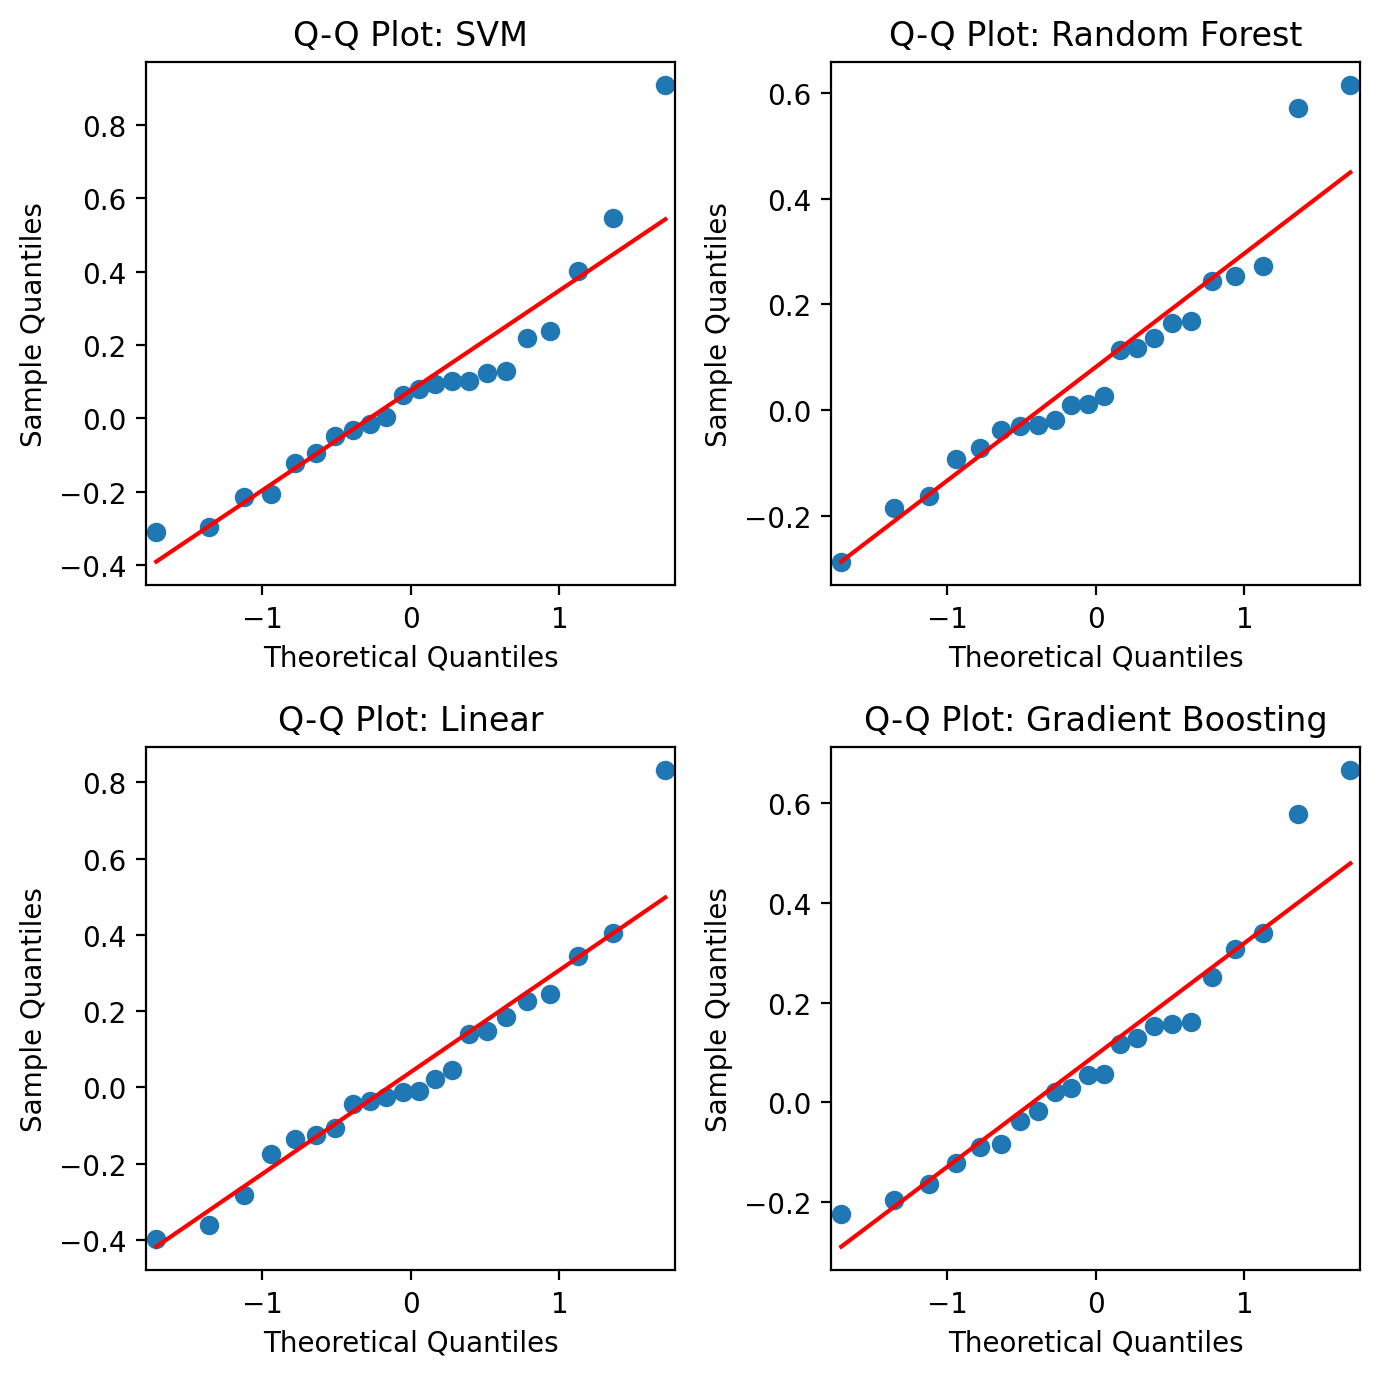

In [ ]:
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import normaltest

# Dictionary to store residuals for each model
model_residuals = {}

# Set up plots with reduced size
fig, axes = plt.subplots(2, 2, figsize=(7, 7))
axes = axes.flatten()

for i, (name, model_instance) in enumerate(models.items()):
    # Generate predictions and calculate residuals
    predictions = model_instance.predict(X_test)
    residuals = y_test - predictions
    model_residuals[name] = residuals

    # Plot Q-Q plot on corresponding subplot axis
    sm.qqplot(residuals, line='s', ax=axes[i])
    axes[i].set_title(f'Q-Q Plot: {name}')

    # Run scipy normaltest
    stat, p_value = normaltest(residuals)
    decision = "Non-normal" if p_value < 0.05 else "Normal"
    print(f"{name}: {decision} (p = {p_value:.6f})")

plt.tight_layout()
plt.show()

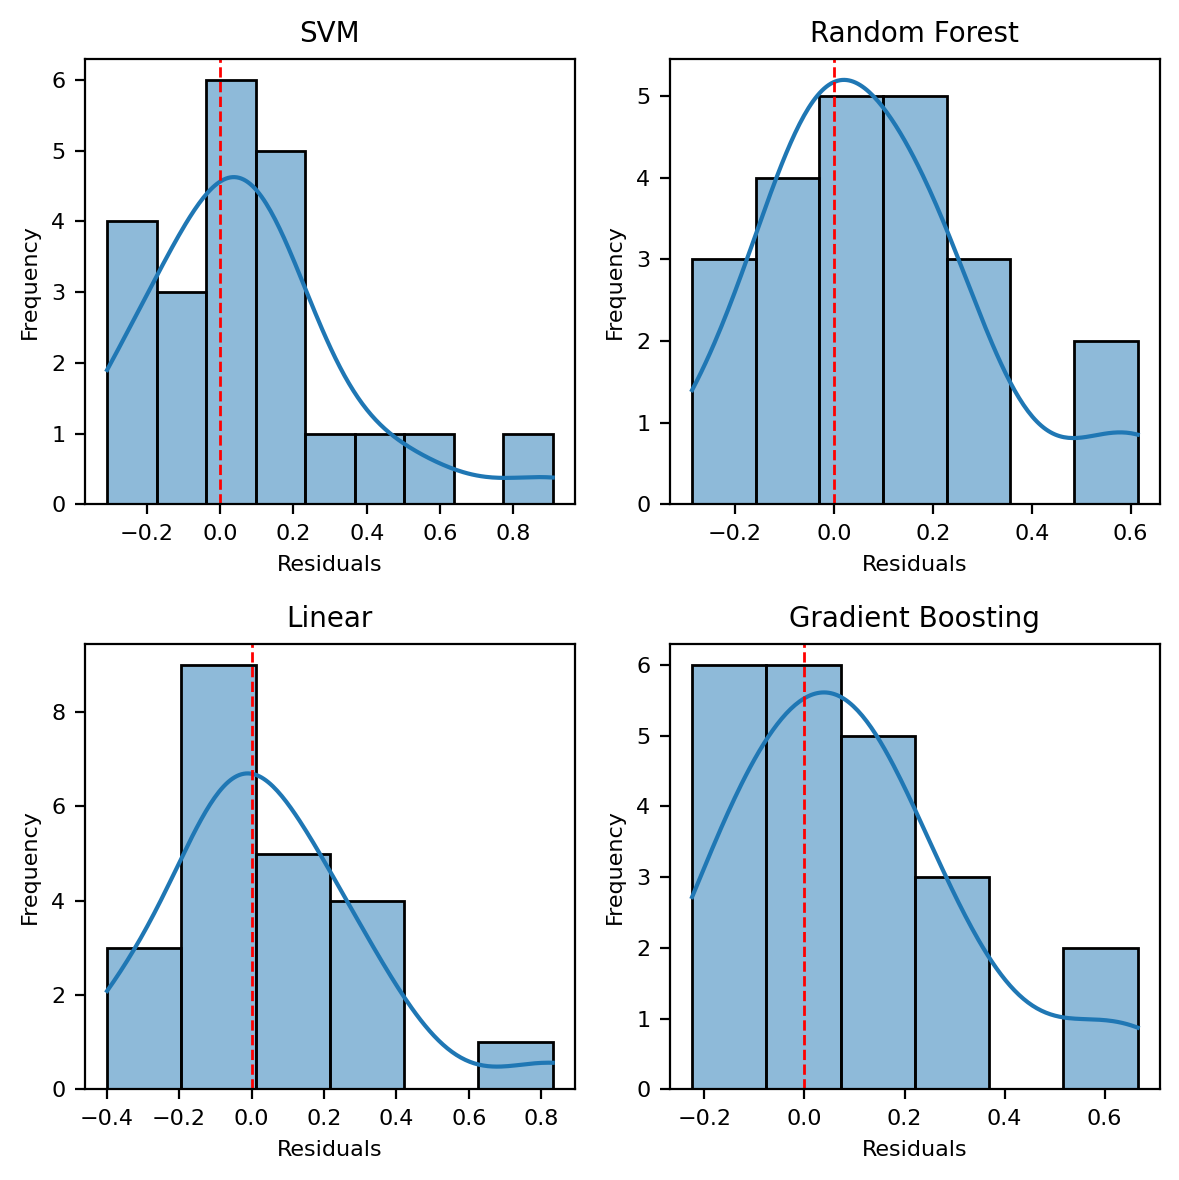

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up a tighter, smaller 2x2 grid of subplots for the histograms
fig, axes = plt.subplots(2, 2, figsize=(6, 6))
axes = axes.flatten()

for i, (name, residuals) in enumerate(model_residuals.items()):
    # Plot histogram with KDE curve using default colors
    sns.histplot(residuals, kde=True, ax=axes[i])
    axes[i].set_title(f'{name}', fontsize=10)
    axes[i].set_xlabel('Residuals', fontsize=8)
    axes[i].set_ylabel('Frequency', fontsize=8)
    axes[i].tick_params(labelsize=8)
    axes[i].axvline(0, color='red', linestyle='--', linewidth=1)

plt.tight_layout()
plt.show()